In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

Evaluate the algorithm(s). We read the cleaned data, apply the algorithm and compare the to ground truth.

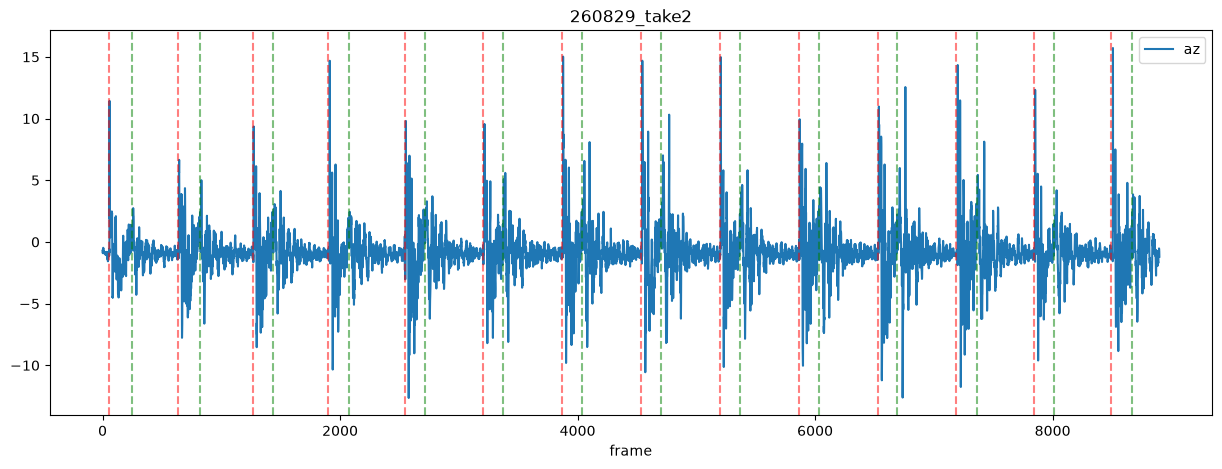

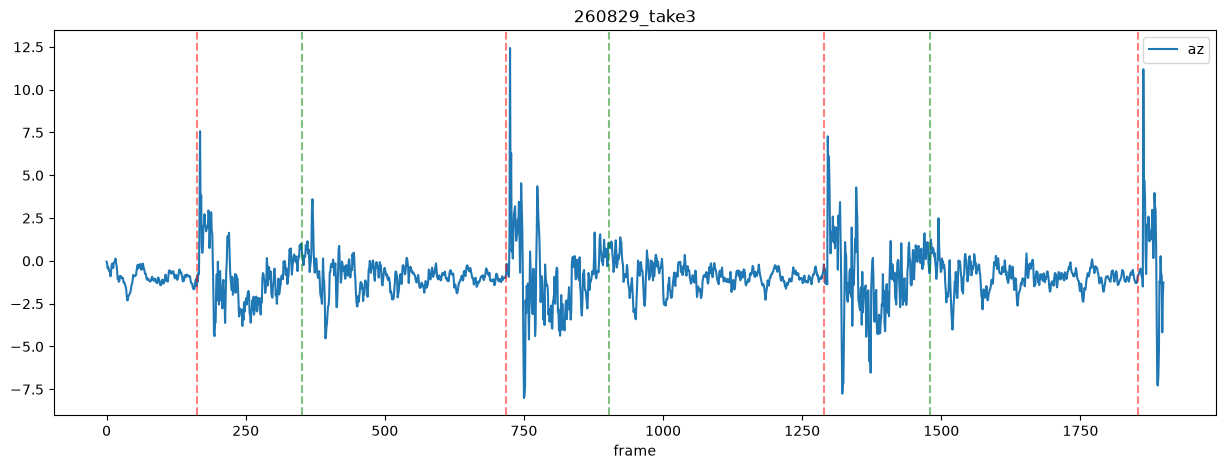

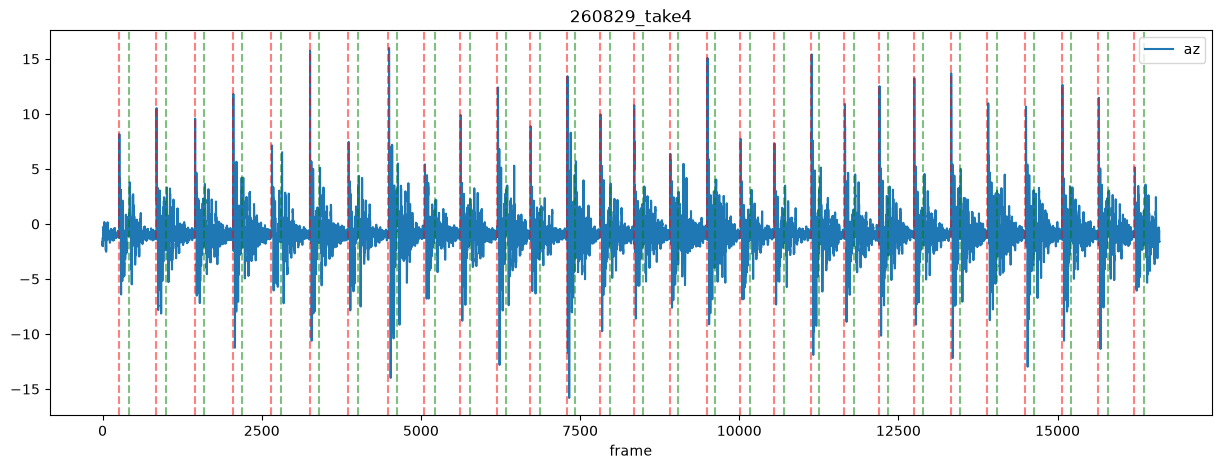

In [61]:
class FileData:
    name: str
    accel: pd.DataFrame
    events: pd.DataFrame
    landing_peaks: np.ndarray
    takeoff_peaks: np.ndarray
    matches = pd.DataFrame

files = ["260829_take2", "260829_take3", "260829_take4"]
file_data = []

for file in files:
    data = FileData()
    data.name = file
    accel = pd.read_csv(f"../../data/cleaned/{file}.csv", index_col="frame")
    accel.plot(figsize=(15, 5), title=file)
    data.accel = accel

    events = pd.read_csv(f"../../data/cleaned/{file}_events.csv", index_col="Sensor_Frame")
    data.events = events
    for idx, row in events.iterrows():
        if row["Event"] == "Takeoff":
            plt.axvline(idx, color='g', linestyle='--', label='Takeoff', alpha=0.5)
        elif row["Event"] == "Landing":
            plt.axvline(idx, color='r', linestyle='--', label='Landing', alpha=0.5)

    file_data.append(data)

Algorithm Implementation

We convert the design algoritm to a state machine. The butterworth filter becomes a FIR filter (see design_filter.ipynb). One problem is the `distance` parameter of `find_peaks()`. It only selects the highest peak in a sliding window. This is hard to emulate in a feed-forward code. We address this with a fixed hold-off and increased minimum height.

In [62]:
class EventType:
    NONE = 0
    TAKEOFF = 1
    LANDING = 2


class DetectorState:
    WAIT_FOR_LANDING = 0
    LANDED_HOLDOFF = 1
    WAIT_FOR_TAKEOFF = 2
    TAKEOFF_HOLDOFF = 3


def spike_and_peak():
    # parameters
    takeoff_threshold = 1.0
    landing_threshold = 3#1.5
    holdoff_landed = 100
    holdoff_takeoff = 400

    # design the FIR filter, 128 taps, cutoff frequency of 8 Hz, sampling frequency of 416 Hz
    taps = signal.firwin(128, 8, fs=416)
    state = DetectorState.WAIT_FOR_LANDING

    sample = yield EventType.NONE
    history = np.full(len(taps), sample)
    history_filtered = np.zeros(3)
    holdoff_count = 0

    while True:
        sample += 1 # remove gravity

        # apply the FIR filter
        history[1:] = history[:-1]
        history[0] = sample
        filtered = taps @ history
        history_filtered[1:] = history_filtered[:-1]
        history_filtered[0] = filtered

        event = EventType.NONE

        takeoff_peak = history_filtered[1] > takeoff_threshold and history_filtered[0] < history_filtered[1] and history_filtered[1] > history_filtered[2]

        if state == DetectorState.WAIT_FOR_LANDING:
            if sample > landing_threshold:
                state = DetectorState.LANDED_HOLDOFF
                event = EventType.LANDING
                holdoff_count = 0
        elif state == DetectorState.LANDED_HOLDOFF:
            if holdoff_count >= holdoff_landed:
                state = DetectorState.WAIT_FOR_TAKEOFF
        elif state == DetectorState.WAIT_FOR_TAKEOFF:
            if takeoff_peak:
                state = DetectorState.TAKEOFF_HOLDOFF
                event = EventType.TAKEOFF
            elif holdoff_count >= 300: # timeout
                state = DetectorState.WAIT_FOR_LANDING
        elif state == DetectorState.TAKEOFF_HOLDOFF:
            if holdoff_count >= holdoff_takeoff:
                state = DetectorState.WAIT_FOR_LANDING

        holdoff_count += 1
        sample = yield event

In [63]:
# scipy implementation for comparison
def spike_and_peak_design(accel, accel_filtered):
    accel_raw = accel+1

    landing_peaks, _ = signal.find_peaks(accel_raw, height=1.5, distance=400)

    # for each peak, find another peak within 300 frames and mark it as a landing event
    # Find additional lower-amplitude peaks for landing detection
    loose_peaks, _ = signal.find_peaks(accel_filtered, height=1, distance=20)

    # For each peak, find the next peak within 300 frames and treat it as a landing event
    takeoff_peaks = []
    for peak in landing_peaks:
        next_peak = loose_peaks[(loose_peaks > peak + 100) & (loose_peaks <= peak + 300)]
        if len(next_peak) > 0:
            takeoff_peaks.append(next_peak[0])

    takeoff_peaks = np.asarray(takeoff_peaks)

    return landing_peaks, takeoff_peaks

Plot the data, the filtered data and the events dectected by the algorithm.

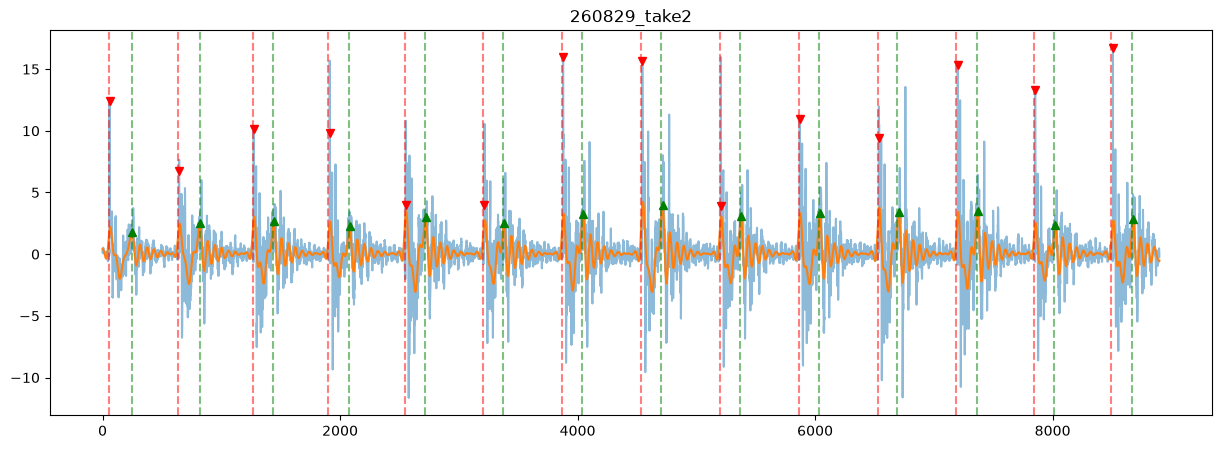

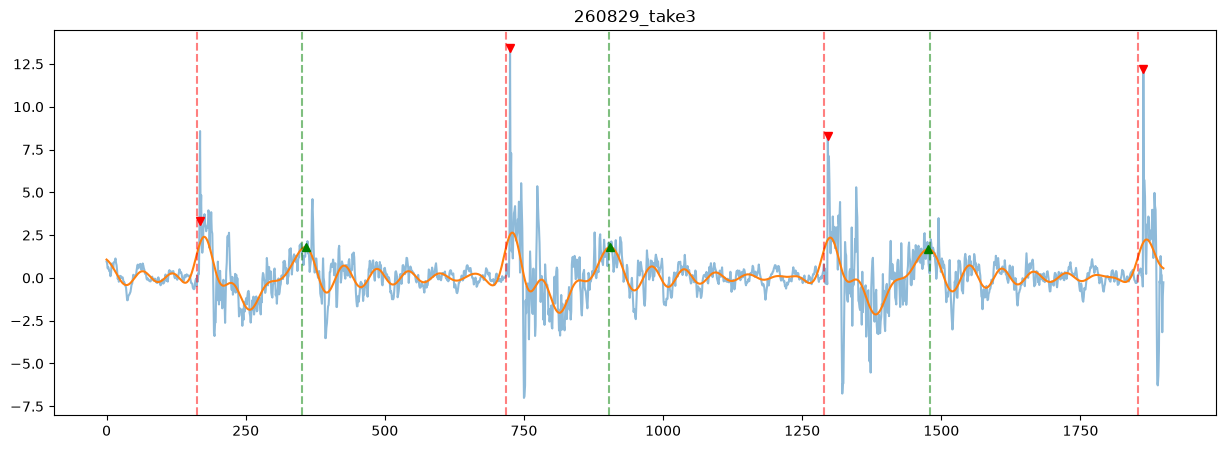

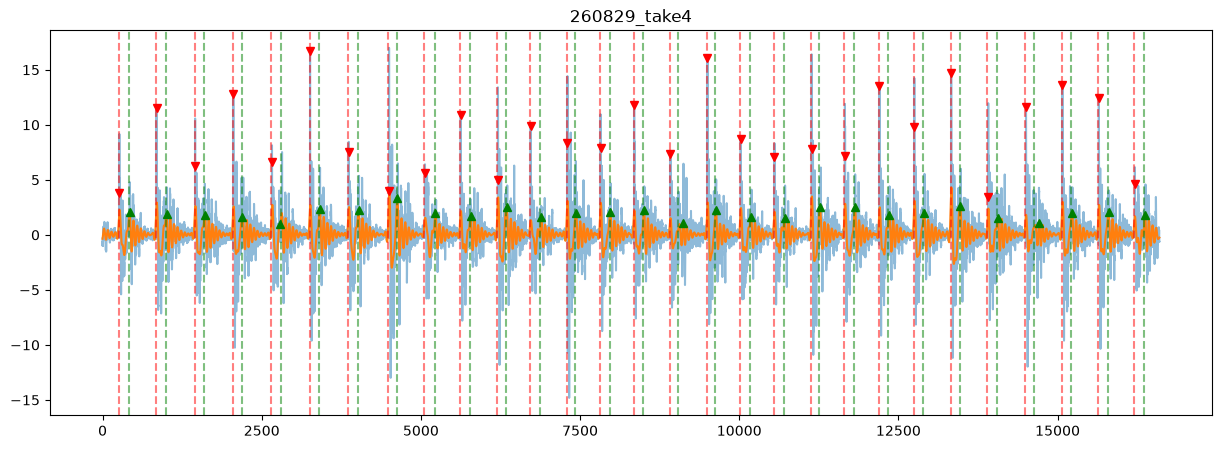

In [64]:
for data in file_data:
    accel = data.accel["az"]
    accel_raw = accel + 1  # remove gravity
    # apply a lowpass filter to the acceleration data
    cutoff = 8  # Cutoff frequency
    fs = 416  # Sampling frequency
    order = 5  # Filter order
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    accel_filtered = signal.filtfilt(b, a, accel_raw)

    # landing_peaks, takeoff_peaks = spike_and_peak_design(accel, accel_filtered)
    detector = spike_and_peak()
    next(detector)  # prime the generator

    # TODO: This should be shorter
    # results = pd.Series((detector.send(x) for x in accel.to_numpy()), index=accel.index)

    landing_frames = []
    takeoff_frames = []

    for frame, sample in enumerate(accel.to_numpy()):
        event = detector.send(sample)

        if event == EventType.LANDING:
            landing_frames.append(frame)
        elif event == EventType.TAKEOFF:
            takeoff_frames.append(frame)

    data.landing_peaks = np.asarray(landing_frames)
    data.takeoff_peaks = np.asarray(takeoff_frames) - 64 # compensate for filter delay

    plt.figure(figsize=(15, 5))
    plt.title(data.name)
    plt.plot(accel_raw, label="Raw Acceleration", alpha=0.5)
    plt.plot(accel_filtered, label="Filtered Acceleration")
    plt.plot(data.landing_peaks, accel_raw[data.landing_peaks], "v", label="Landing", color="r")
    plt.plot(data.takeoff_peaks, accel_filtered[data.takeoff_peaks], "^", label="Takeoff", color="g")
    # plot takeoff and landing events
    for idx, row in data.events.iterrows():
        if row["Event"] == "Takeoff":
            plt.axvline(idx, color='g', linestyle='--', label='Takeoff', alpha=0.5)
        elif row["Event"] == "Landing":
            plt.axvline(idx, color='r', linestyle='--', label='Landing', alpha=0.5)

# plt.xlim(2000, 5000)

Evaluation

For every event in the ground thruth find the nearest detected event.

In [65]:
max_distance = 200

for data in file_data:
    detected_by_event = {
        "Takeoff": data.takeoff_peaks,
        "Landing": data.landing_peaks,
    }

    matches = []

    for event_frame, row in data.events.iterrows():
        event_type = row["Event"]
        detected = detected_by_event[event_type]

        nearest = detected[np.argmin(np.abs(detected - event_frame))]
        distance = nearest - event_frame

        matches.append({
            "Event": event_type,
            "Recorded_Frame": event_frame,
            "Detected_Frame": nearest if distance <= max_distance else None,
            "Distance_Frames": distance if distance <= max_distance else None,
            "Matched": distance <= max_distance,
        })

    data.matches_df = pd.DataFrame(matches)

In [66]:
#debug
file_data[1].matches_df

,Event,Recorded_Frame,Detected_Frame,Distance_Frames,Matched
0,Landing,161.866667,167,5.133333,True
1,Takeoff,350.800000,358,7.200000,True
2,Landing,718.266667,725,6.733333,True
3,Takeoff,902.000000,904,2.000000,True
4,Landing,1288.533333,1296,7.466667,True
5,Takeoff,1479.200000,1476,-3.200000,True
6,Landing,1853.600000,1863,9.400000,True


Plot histograms

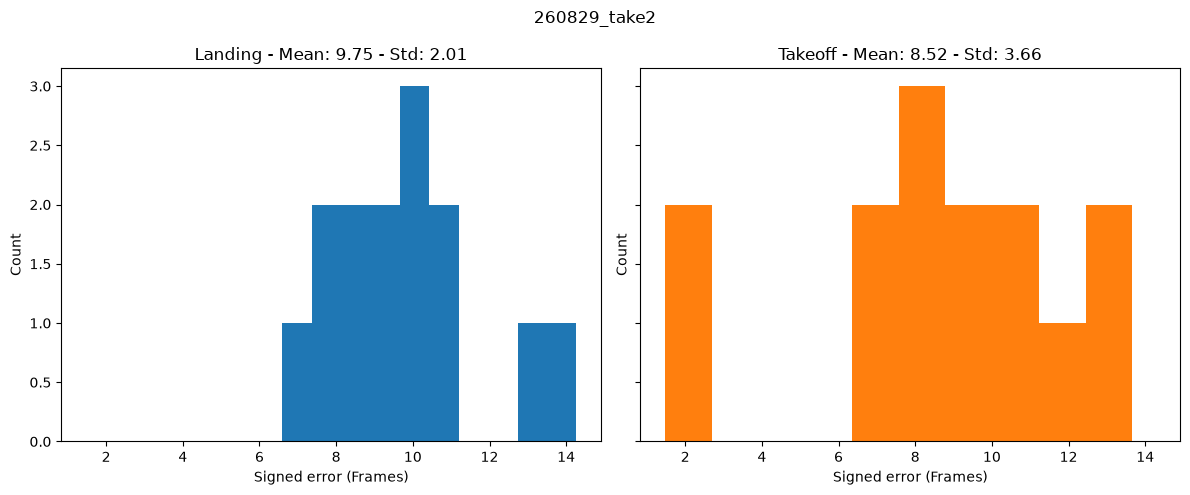

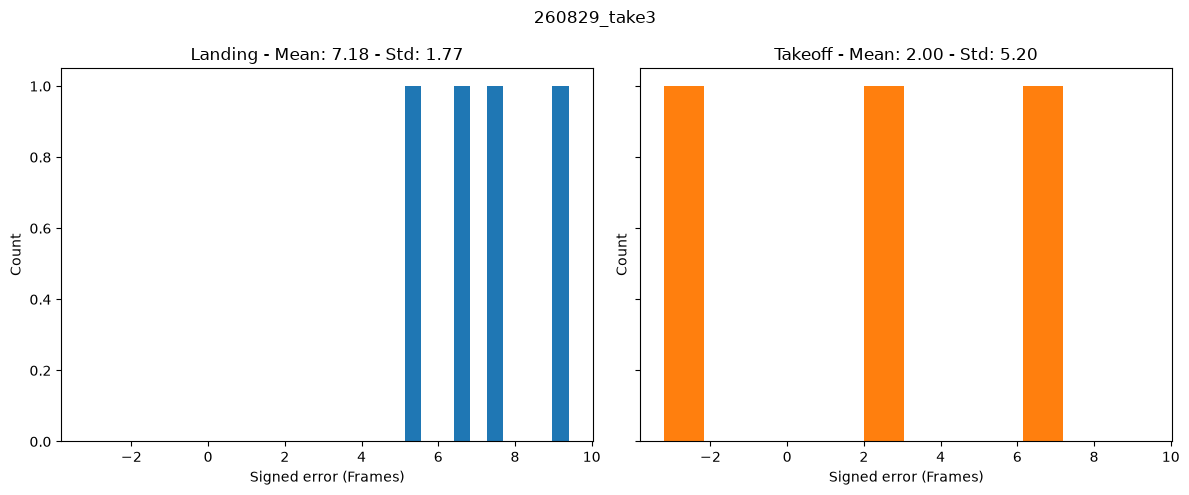

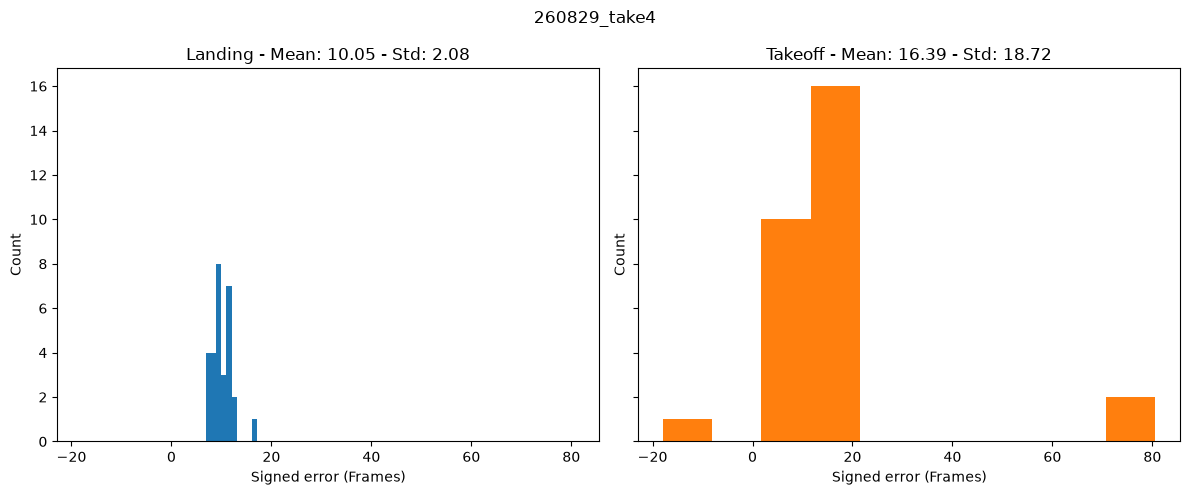

In [67]:
colors = {
    "Landing": "C0",
    "Takeoff": "C1",
}

for data in file_data:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)


    for ax, event in zip(axes, ["Landing", "Takeoff"]):
        vals = data.matches_df.loc[data.matches_df["Event"] == event, "Distance_Frames"] #* ms_per_frame
        ax.hist(vals, bins=10, color=colors[event], label=event)
        ax.set_title(f"{event} - Mean: {vals.mean():.2f} - Std: {vals.std():.2f}")
        ax.set_xlabel("Signed error (Frames)")
        ax.set_ylabel("Count")

    fig.suptitle(data.name)
    plt.tight_layout()
    plt.show()


Some statistics

In [77]:
ms_per_frame = 1000 / fs

all_matches = pd.concat(
    [data.matches_df.assign(File=data.name) for data in file_data],
    ignore_index=True,
)

all_matches = all_matches.assign(
    Error_ms=all_matches["Distance_Frames"] * ms_per_frame,
    Absolute_Error_ms=all_matches["Distance_Frames"].abs() * ms_per_frame,
)

def compute_stats(grouping):
    return grouping.agg(
        count=("Matched", "size"),
        matched=("Matched", "sum"),
        match_rate=("Matched", "mean"),
        mean_error_ms=("Error_ms", "mean"),
        std_error_ms=("Error_ms", "std"),
        mean_absolute_error_ms=("Absolute_Error_ms", "mean"),
        std_absolute_error_ms=("Absolute_Error_ms", "std"),
    )

file_event_stats = compute_stats(all_matches.groupby(["File", "Event"]))
all_event_stats = compute_stats(all_matches.groupby("Event"))
all_event_stats.index = pd.MultiIndex.from_product([["Overall"], all_event_stats.index], names=["File", "Event"])

display(pd.concat([file_event_stats, all_event_stats]))

count  matched  match_rate  mean_error_ms  std_error_ms  \
File         Event                                                              
260829_take2 Landing     14       14         1.0      23.431777      4.836035   
             Takeoff     14       14         1.0      20.478480      8.800348   
260829_take3 Landing      4        4         1.0      17.267628      4.254850   
             Takeoff      3        3         1.0       4.807692     12.500000   
260829_take4 Landing     29       29         1.0      24.160035      5.001925   
             Takeoff     29       29         1.0      39.400973     44.990149   
Overall      Landing     47       47         1.0      23.356519      5.162544   
             Takeoff     46       46         1.0      31.385870     37.606822   

                      mean_absolute_error_ms  std_absolute_error_ms  
File         Event                                                   
260829_take2 Landing               23.431777               4.836035  
             Takeoff               20.478480               8.800348  
260829_take3 Landing               17.267628               4.254850  
             Takeoff                9.935897               6.545057  
260829_take4 Landing               24.160035               5.001925  
             Takeoff               42.374005              42.098824  
Overall      Landing               23.356519               5.162544  
             Takeoff               33.594621              35.602779

Time of flight calculation

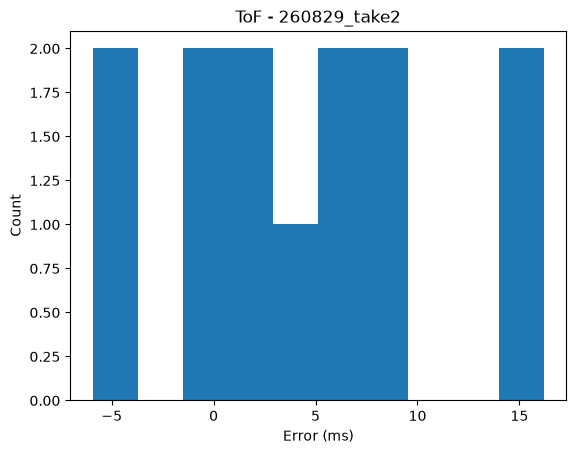

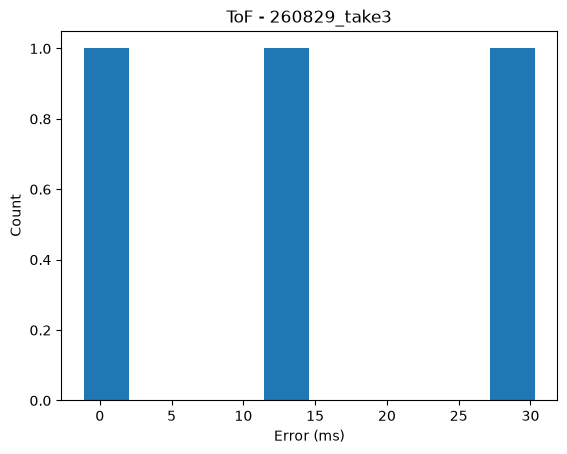

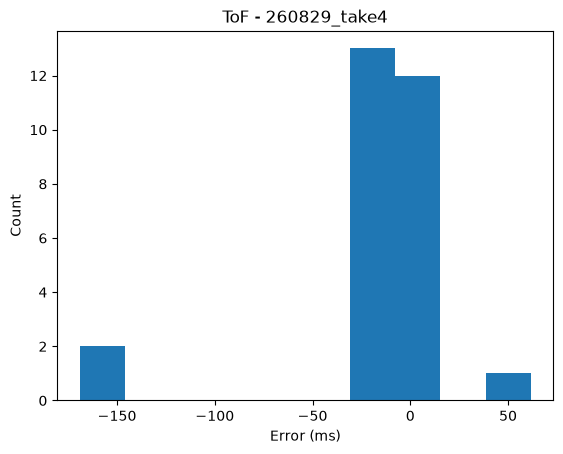

In [74]:
flight_pairs = []

for file_name, file_matches in all_matches.groupby("File"):
    ordered_matches = file_matches.loc[file_matches["Matched"]].sort_values("Recorded_Frame")
    pending_takeoff = None

    for row in ordered_matches.itertuples(index=False):
        if row.Event == "Takeoff":
            pending_takeoff = row
        elif row.Event == "Landing" and pending_takeoff is not None:
            recorded_ms = (row.Recorded_Frame - pending_takeoff.Recorded_Frame) * ms_per_frame
            detected_ms = (row.Detected_Frame - pending_takeoff.Detected_Frame) * ms_per_frame

            flight_pairs.append({
                "File": file_name,
                "Takeoff_Frame": pending_takeoff.Recorded_Frame,
                "Landing_Frame": row.Recorded_Frame,
                "Recorded_Flight_ms": recorded_ms,
                "Detected_Flight_ms": detected_ms,
                "Error_ms": detected_ms - recorded_ms,
            })
            pending_takeoff = None

flight_errors_df = pd.DataFrame(flight_pairs)

for file_name, group in flight_errors_df.groupby("File"):
    plt.hist(group["Error_ms"].dropna(), bins=10)
    plt.title(f"ToF - {file_name}")
    plt.xlabel("Error (ms)")
    plt.ylabel("Count")
    plt.show()


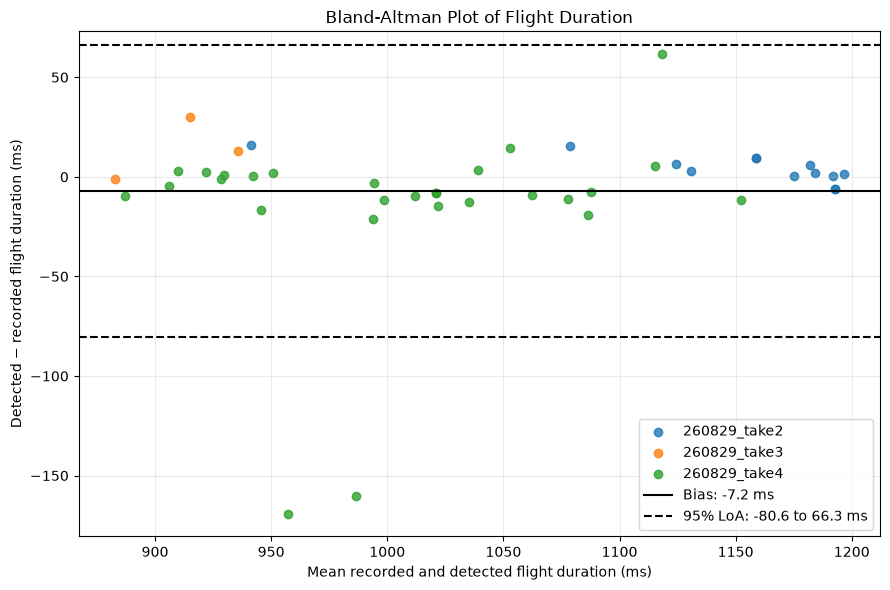

In [78]:
ba_data = flight_errors_df.assign(
    Mean_Flight_ms=(flight_errors_df["Recorded_Flight_ms"] + flight_errors_df["Detected_Flight_ms"]) / 2,
    Difference_ms=flight_errors_df["Detected_Flight_ms"] - flight_errors_df["Recorded_Flight_ms"],
)

fig, ax = plt.subplots(figsize=(9, 6))
colors = plt.get_cmap("tab10")
for color_index, (file_name, group) in enumerate(ba_data.groupby("File")):
    ax.scatter(
        group["Mean_Flight_ms"],
        group["Difference_ms"],
        color=colors(color_index),
        label=file_name,
        alpha=0.8,
    )

bias = ba_data["Difference_ms"].mean()
std_difference = ba_data["Difference_ms"].std(ddof=1)
upper_loa = bias + 1.96 * std_difference
lower_loa = bias - 1.96 * std_difference

ax.axhline(bias, color="black", linestyle="-", label=f"Bias: {bias:.1f} ms")
ax.axhline(upper_loa, color="black", linestyle="--", label=f"95% LoA: {lower_loa:.1f} to {upper_loa:.1f} ms")
ax.axhline(lower_loa, color="black", linestyle="--")
ax.set(
    title="Bland-Altman Plot of Flight Duration",
    xlabel="Mean recorded and detected flight duration (ms)",
    ylabel="Detected − recorded flight duration (ms)",
)
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()

In [75]:
flight_error_stats = flight_errors_df.groupby("File").agg(
    flight_count=("Error_ms", "count"),
    flight_mean_error_ms=("Error_ms", "mean"),
    flight_std_error_ms=("Error_ms", lambda errors: errors.std(ddof=0)),
    flight_mean_absolute_error_ms=("Error_ms", lambda errors: errors.abs().mean()),
)

event_match_stats = all_matches.groupby("File").agg(
    event_count=("Matched", "size"),
    matched_events=("Matched", "sum"),
    match_rate=("Matched", "mean"),
)

summary = event_match_stats.join(flight_error_stats)
overall_stats = pd.DataFrame(
    [{
        "event_count": all_matches["Matched"].size,
        "matched_events": all_matches["Matched"].sum(),
        "match_rate": all_matches["Matched"].mean(),
        "flight_count": len(flight_errors_df),
        "flight_mean_error_ms": flight_errors_df["Error_ms"].mean(),
        "flight_std_error_ms": flight_errors_df["Error_ms"].std(ddof=0),
        "flight_mean_absolute_error_ms": flight_errors_df["Error_ms"].abs().mean(),
    }],
    index=["Overall"],
)

summary = pd.concat([summary, overall_stats])
display(summary)

,event_count,matched_events,match_rate,flight_count,flight_mean_error_ms,flight_std_error_ms,flight_mean_absolute_error_ms
260829_take2,28,28,1.0,13,4.487179,6.696636,6.311637
260829_take3,7,7,1.0,3,14.102564,12.841196,14.850427
260829_take4,58,58,1.0,28,-14.835165,44.132229,21.485806
Overall,93,93,1.0,44,-7.153263,37.044577,16.550117
